# FASTA and GenBank Alignment Exercise

A 17-step exercise: load sequences from a FASTA and a GenBank file, align them (local and global), compare Hamming and Levenshtein distances, transcribe and translate, and plot sequence properties. The task is in `exercises/Assignment Exercise.md`.

In [1]:
import matplotlib.pyplot as plt
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.Align import PairwiseAligner
from itertools import islice
from Bio.SeqUtils import seq3
from Bio.SeqUtils import gc_fraction
from Bio.SeqUtils import MeltingTemp as mt
from Bio.SeqUtils import molecular_weight as mw
from Levenshtein import distance
from collections import Counter

In [2]:
# 1
seq_a = SeqIO.read('dataset/sequence.fasta', 'fasta').seq
print(seq_a)

AGCTCCTAGGACCAGAGCCAGGAAGAGACTAGAAAGAAAACAGCTCGTGTCAACATGACTTCCAAACTGGCTGTTGCCTTCTTGGCAGTTTTCCTGCTTTCTGCAGCTCTCTGTGAGGCTGCAGTTCTGGCAAGAGTAAGTGCAGAACTTCGATGCCAGTGCATAAATACGCATTCCACACCTTTCCACCCCAAATTTATCAAGGAACTGAGAGTGATTGAGAGTGGACCCCACTGTGAAAATTCAGAAATCATTGTTAAGCTTGTCAATGGAAAAGAGGTCTGCCTGGACCCCAAGGAAAAGTGGGTGCAGAAGGTTGTACAGATATTTTTGAAGAGAACTGAGAAGCAACAACAACAGCAGTAACAACAACAAGCAAAAACCCATTCTCCGTGGCTCCCAAGAATTTCTCAGTAAAGATGCCAACACAACTTCAATCAAATCTACATCTATGCCTCATTCCTGTGCTGGTCAGACATAGGGTTGCCAGAGAAATCACAGGATGCCCAGTTATATTTGAATATTAAGTAAAACAATGAATTATTTCCAGTGTCCCATGCACGTTGTTCTATACTAACATTTTAAAAATTCTTCGTTGTTTGCTGTAAATTCAAATTTAGCTGGAAATCCTGTTTTGGCTTTTTGTTATTATAATTATTAATATTATTAAATCTTGCAACCCTAGGCTGCTGGCCAGCATTCACAAGTCTCTGCTCAACTGCACCTCAGTTTCTTCTTTATCCCCAAACTGGAGAAAAAGCTTCAGCCCCCATCCTACCTTGAGGACATGTGGATGTACTTTAACTTTGATTGACAGTCATGTAAAATATTTTCAAGTGTAATTTATTCACTTATTTATTATTTATATATTTATTTTAGTATCAAATAGAGTAATGTTTGTGCATGAATTTGGAGAAATGGAAAAGAAGCATTGTTGATAGGATAGTCTCATGATAGTAGTGAATTTCTATTTATTTTACATATTAAGTGGTGTATTATG

In [3]:
# 2
seq_b = SeqIO.read('dataset/sequence.gb', 'gb').seq
print(seq_b)

GTGACTGCGCACCACAACTTTCCTTCGGAGACCTCATAGGACCGGGAGTGTTTCCAGCCTTGCGGGCCACCCCAGCCTTCTGCAAAGCCTCGCCCATGCCGCCTGCGTTTTCAGGGTCCTGCTCAGCTCTGACCCTGAAGTCATCTCCAGTGCTTTCCTCTTCTTCTAAGGGCCATGGCATGGCTTCATGTAATACAGATTTGGGGCAGATC


In [4]:
# 3
seq_c = seq_a[-40:][::-1]
print(seq_c)

AAAAAAAAACTGAAAATATTATTTAAAATAACATTTACAA


In [5]:
# 4
seq_d = seq_b[:50]
print(seq_d)

GTGACTGCGCACCACAACTTTCCTTCGGAGACCTCATAGGACCGGGAGTG


The exercise asks for the best alignment score "using default alignment scores". Here that means the classic `xx` scoring: match = 1, mismatch = 0 and no gap penalty. Biopython's `PairwiseAligner` penalises gaps by default, which would give lower scores. With free gaps there are millions of equally good alignments, so only the first few are shown.

In [6]:
# 5
# xx scoring: match = 1, mismatch = 0, no gap penalty
aligner = PairwiseAligner(mode='local', match_score=1, mismatch_score=0, open_gap_score=0, extend_gap_score=0)
alignments = aligner.align(seq_c, seq_d)
print(f'Best local alignment score: {alignments.score}')
print(f'Number of optimal alignments: {len(alignments)} (showing the first 3)')
for a in islice(alignments, 3):
    print(a)

Best local alignment score: 22.0
Number of optimal alignments: 83172024 (showing the first 3)
target            0 AAAAAAAAACTG---A--A-AA-TATTA--TTT---A-A----AATA--AC----A-T 34
                  0 |--------|||---|--|-||-|-||---||----|-|----|-||--||----|-| 58
query             3 A--------CTGCGCACCACAACT-TT-CCTT-CGGAGACCTCA-TAGGACCGGGAGT 49

target            1 AAAAAAAACTG---A--A-AA-TATTA--TTT---A-A----AATA--AC----A-T 34
                  0 |-------|||---|--|-||-|-||---||----|-|----|-||--||----|-| 57
query             3 A-------CTGCGCACCACAACT-TT-CCTT-CGGAGACCTCA-TAGGACCGGGAGT 49

target            2 AAAAAAACTG---A--A-AA-TATTA--TTT---A-A----AATA--AC----A-T 34
                  0 |------|||---|--|-||-|-||---||----|-|----|-||--||----|-| 56
query             3 A------CTGCGCACCACAACT-TT-CCTT-CGGAGACCTCA-TAGGACCGGGAGT 49



In [7]:
# 6
# xx scoring: match = 1, mismatch = 0, no gap penalty
aligner = PairwiseAligner(mode='global', match_score=1, mismatch_score=0, open_gap_score=0, extend_gap_score=0)
alignments = aligner.align(seq_c, seq_d)
print(f'Best global alignment score: {alignments.score}')
print(f'Number of optimal alignments: {len(alignments)} (showing the first 3)')
for a in islice(alignments, 3):
    print(a)

Best global alignment score: 22.0
Number of optimal alignments: 35136997560 (showing the first 3)
target            0 ---AAAAAAAAACTG---A--A-AA-TATTA--TTT---A-AAA--TAACATTTA---C-
                  0 ---|--------|||---|--|-||-|-||---||----|-|----|--|||--|---|-
query             0 GTGA--------CTGCGCACCACAACT-TT-CCTT-CGGAGA--CCT--CAT--AGGACC

target           38 ---AA--- 40
                 60 ---|---- 68
query            43 GGGA-GTG 50

target            0 A---AAAAAAAACTG---A--A-AA-TATTA--TTT---A-AAA--TAACATTTA---C-
                  0 ----|-------|||---|--|-||-|-||---||----|-|----|--|||--|---|-
query             0 -GTGA-------CTGCGCACCACAACT-TT-CCTT-CGGAGA--CCT--CAT--AGGACC

target           38 ---AA--- 40
                 60 ---|---- 68
query            43 GGGA-GTG 50

target            0 -A--AAAAAAAACTG---A--A-AA-TATTA--TTT---A-AAA--TAACATTTA---C-
                  0 ----|-------|||---|--|-||-|-||---||----|-|----|--|||--|---|-
query             0 G-TGA-------CTGCGCACCACAACT-TT-CCTT-CG

In [8]:
# 7
def hamming(c, d):
    mismatch = []
    for x, y in zip(c, d):
        if x != y:
            mismatch.append((x, y))
    return len(mismatch)

print(hamming(seq_c, seq_d))

30


In [9]:
# 8
print(distance(seq_c, seq_d))

33


In [10]:
# 9
mrna_c = seq_c.transcribe()
print(mrna_c)

AAAAAAAAACUGAAAAUAUUAUUUAAAAUAACAUUUACAA


In [11]:
# 10
mrna_a = seq_a.transcribe()
print(mrna_a)

AGCUCCUAGGACCAGAGCCAGGAAGAGACUAGAAAGAAAACAGCUCGUGUCAACAUGACUUCCAAACUGGCUGUUGCCUUCUUGGCAGUUUUCCUGCUUUCUGCAGCUCUCUGUGAGGCUGCAGUUCUGGCAAGAGUAAGUGCAGAACUUCGAUGCCAGUGCAUAAAUACGCAUUCCACACCUUUCCACCCCAAAUUUAUCAAGGAACUGAGAGUGAUUGAGAGUGGACCCCACUGUGAAAAUUCAGAAAUCAUUGUUAAGCUUGUCAAUGGAAAAGAGGUCUGCCUGGACCCCAAGGAAAAGUGGGUGCAGAAGGUUGUACAGAUAUUUUUGAAGAGAACUGAGAAGCAACAACAACAGCAGUAACAACAACAAGCAAAAACCCAUUCUCCGUGGCUCCCAAGAAUUUCUCAGUAAAGAUGCCAACACAACUUCAAUCAAAUCUACAUCUAUGCCUCAUUCCUGUGCUGGUCAGACAUAGGGUUGCCAGAGAAAUCACAGGAUGCCCAGUUAUAUUUGAAUAUUAAGUAAAACAAUGAAUUAUUUCCAGUGUCCCAUGCACGUUGUUCUAUACUAACAUUUUAAAAAUUCUUCGUUGUUUGCUGUAAAUUCAAAUUUAGCUGGAAAUCCUGUUUUGGCUUUUUGUUAUUAUAAUUAUUAAUAUUAUUAAAUCUUGCAACCCUAGGCUGCUGGCCAGCAUUCACAAGUCUCUGCUCAACUGCACCUCAGUUUCUUCUUUAUCCCCAAACUGGAGAAAAAGCUUCAGCCCCCAUCCUACCUUGAGGACAUGUGGAUGUACUUUAACUUUGAUUGACAGUCAUGUAAAAUAUUUUCAAGUGUAAUUUAUUCACUUAUUUAUUAUUUAUAUAUUUAUUUUAGUAUCAAAUAGAGUAAUGUUUGUGCAUGAAUUUGGAGAAAUGGAAAAGAAGCAUUGUUGAUAGGAUAGUCUCAUGAUAGUAGUGAAUUUCUAUUUAUUUUACAUAUUAAGUGGUGUAUUAUG

In [12]:
# 11
mrna_z = mrna_c + mrna_a
print(mrna_z)

AAAAAAAAACUGAAAAUAUUAUUUAAAAUAACAUUUACAAAGCUCCUAGGACCAGAGCCAGGAAGAGACUAGAAAGAAAACAGCUCGUGUCAACAUGACUUCCAAACUGGCUGUUGCCUUCUUGGCAGUUUUCCUGCUUUCUGCAGCUCUCUGUGAGGCUGCAGUUCUGGCAAGAGUAAGUGCAGAACUUCGAUGCCAGUGCAUAAAUACGCAUUCCACACCUUUCCACCCCAAAUUUAUCAAGGAACUGAGAGUGAUUGAGAGUGGACCCCACUGUGAAAAUUCAGAAAUCAUUGUUAAGCUUGUCAAUGGAAAAGAGGUCUGCCUGGACCCCAAGGAAAAGUGGGUGCAGAAGGUUGUACAGAUAUUUUUGAAGAGAACUGAGAAGCAACAACAACAGCAGUAACAACAACAAGCAAAAACCCAUUCUCCGUGGCUCCCAAGAAUUUCUCAGUAAAGAUGCCAACACAACUUCAAUCAAAUCUACAUCUAUGCCUCAUUCCUGUGCUGGUCAGACAUAGGGUUGCCAGAGAAAUCACAGGAUGCCCAGUUAUAUUUGAAUAUUAAGUAAAACAAUGAAUUAUUUCCAGUGUCCCAUGCACGUUGUUCUAUACUAACAUUUUAAAAAUUCUUCGUUGUUUGCUGUAAAUUCAAAUUUAGCUGGAAAUCCUGUUUUGGCUUUUUGUUAUUAUAAUUAUUAAUAUUAUUAAAUCUUGCAACCCUAGGCUGCUGGCCAGCAUUCACAAGUCUCUGCUCAACUGCACCUCAGUUUCUUCUUUAUCCCCAAACUGGAGAAAAAGCUUCAGCCCCCAUCCUACCUUGAGGACAUGUGGAUGUACUUUAACUUUGAUUGACAGUCAUGUAAAAUAUUUUCAAGUGUAAUUUAUUCACUUAUUUAUUAUUUAUAUAUUUAUUUUAGUAUCAAAUAGAGUAAUGUUUGUGCAUGAAUUUGGAGAAAUGGAAAAGAAGCAUUGUUGAUAGGAUAGUCUCAUGAUAGUAG

In [13]:
# 12
protein_z = mrna_z.translate()
print(protein_z)
print(seq3(protein_z))

KKKLKILFKITFTKLLGPEPGRD*KENSSCQHDFQTGCCLLGSFPAFCSSL*GCSSGKSKCRTSMPVHKYAFHTFPPQIYQGTESD*EWTPL*KFRNHC*ACQWKRGLPGPQGKVGAEGCTDIFEEN*EATTTAVTTTSKNPFSVAPKNFSVKMPTQLQSNLHLCLIPVLVRHRVAREITGCPVIFEY*VKQ*IISSVPCTLFYTNILKILRCLL*IQI*LEILFWLFVIIIINIIKSCNPRLLASIHKSLLNCTSVSSLSPNWRKSFSPHPTLRTCGCTLTLIDSHVKYFQV*FIHLFIIYIFILVSNRVMFVHEFGEMEKKHC**DSLMIVVNFYLFYILSGVLWNYFYQGHCIMIRVARFGKLLNEQNTQLSTLLFI*NFI*TSYPTFETPSLVL*LQALLCSAVLNDVNFKLGLVFSKQQKFTRQYQ*SHFLLFILYFVQLDSHNFI*IIVCFKTNFFYLNLFLCISKEILLVFFMLQNCECNYRTFTIKFIIKVKKK
LysLysLysLeuLysIleLeuPheLysIleThrPheThrLysLeuLeuGlyProGluProGlyArgAspTerLysGluAsnSerSerCysGlnHisAspPheGlnThrGlyCysCysLeuLeuGlySerPheProAlaPheCysSerSerLeuTerGlyCysSerSerGlyLysSerLysCysArgThrSerMetProValHisLysTyrAlaPheHisThrPheProProGlnIleTyrGlnGlyThrGluSerAspTerGluTrpThrProLeuTerLysPheArgAsnHisCysTerAlaCysGlnTrpLysArgGlyLeuProGlyProGlnGlyLysValGlyAlaGluGlyCysThrAspIlePheGluGluAsnTerGluAlaThrThrThrAlaValThrThrThrSerLysAsnProPheSerValAlaProLysAsnPheSerValLysMetProThrGlnLeuGlnSerAsnLeuHisLeuCysLe

In [14]:
# 13
seq_z = mrna_z.back_transcribe()
print(seq_z)

AAAAAAAAACTGAAAATATTATTTAAAATAACATTTACAAAGCTCCTAGGACCAGAGCCAGGAAGAGACTAGAAAGAAAACAGCTCGTGTCAACATGACTTCCAAACTGGCTGTTGCCTTCTTGGCAGTTTTCCTGCTTTCTGCAGCTCTCTGTGAGGCTGCAGTTCTGGCAAGAGTAAGTGCAGAACTTCGATGCCAGTGCATAAATACGCATTCCACACCTTTCCACCCCAAATTTATCAAGGAACTGAGAGTGATTGAGAGTGGACCCCACTGTGAAAATTCAGAAATCATTGTTAAGCTTGTCAATGGAAAAGAGGTCTGCCTGGACCCCAAGGAAAAGTGGGTGCAGAAGGTTGTACAGATATTTTTGAAGAGAACTGAGAAGCAACAACAACAGCAGTAACAACAACAAGCAAAAACCCATTCTCCGTGGCTCCCAAGAATTTCTCAGTAAAGATGCCAACACAACTTCAATCAAATCTACATCTATGCCTCATTCCTGTGCTGGTCAGACATAGGGTTGCCAGAGAAATCACAGGATGCCCAGTTATATTTGAATATTAAGTAAAACAATGAATTATTTCCAGTGTCCCATGCACGTTGTTCTATACTAACATTTTAAAAATTCTTCGTTGTTTGCTGTAAATTCAAATTTAGCTGGAAATCCTGTTTTGGCTTTTTGTTATTATAATTATTAATATTATTAAATCTTGCAACCCTAGGCTGCTGGCCAGCATTCACAAGTCTCTGCTCAACTGCACCTCAGTTTCTTCTTTATCCCCAAACTGGAGAAAAAGCTTCAGCCCCCATCCTACCTTGAGGACATGTGGATGTACTTTAACTTTGATTGACAGTCATGTAAAATATTTTCAAGTGTAATTTATTCACTTATTTATTATTTATATATTTATTTTAGTATCAAATAGAGTAATGTTTGTGCATGAATTTGGAGAAATGGAAAAGAAGCATTGTTGATAGGATAGTCTCATGATAGTAG

73.33741776092742 80.28026056254394


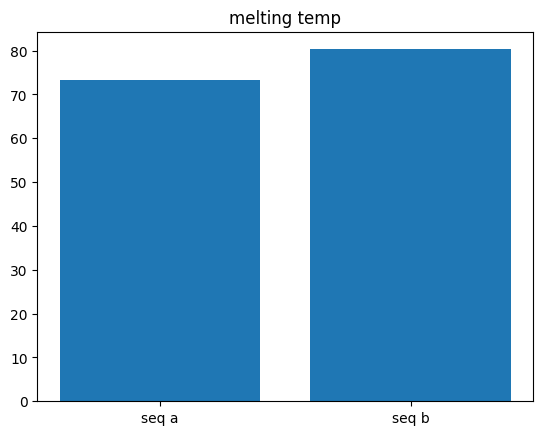

In [15]:
# 14
mt_a = mt.Tm_GC(seq_a)
mt_b = mt.Tm_GC(seq_b)
print(mt_a, mt_b)

plt.bar(['seq a', 'seq b'], [mt_a, mt_b])
plt.title('melting temp')
plt.show()

33.765347885402456 56.60377358490566


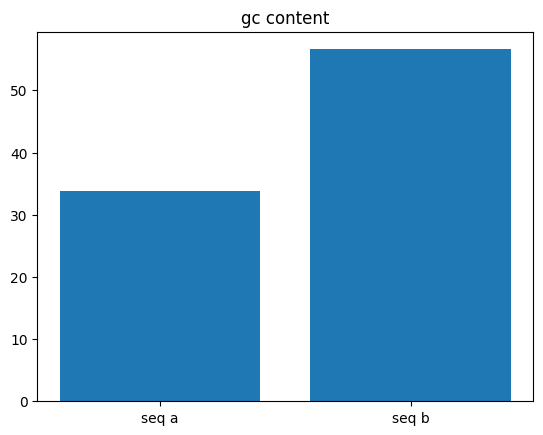

In [16]:
# 15
a_gc = gc_fraction(seq_a) * 100
b_gc = gc_fraction(seq_b) * 100
print(a_gc, b_gc)

plt.bar(['seq a', 'seq b'], [a_gc, b_gc])
plt.title('gc content')
plt.show()

452580.7299 65080.3269


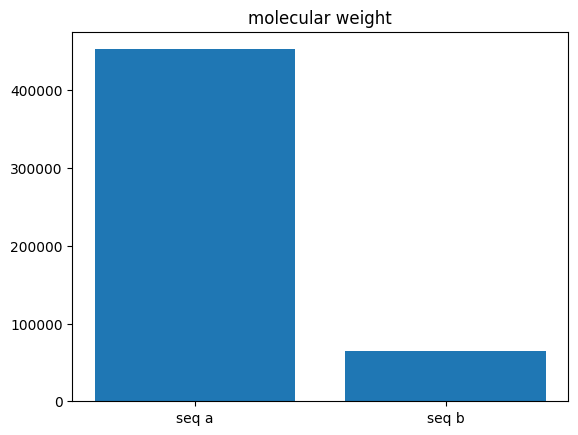

In [17]:
# 16
a_mw = mw(seq_a)
b_mw = mw(seq_b)
print(a_mw, b_mw)

plt.bar(['seq a', 'seq b'], [a_mw, b_mw])
plt.title('molecular weight')
plt.show()

Counter({'T': 516, 'A': 491, 'C': 252, 'G': 247})


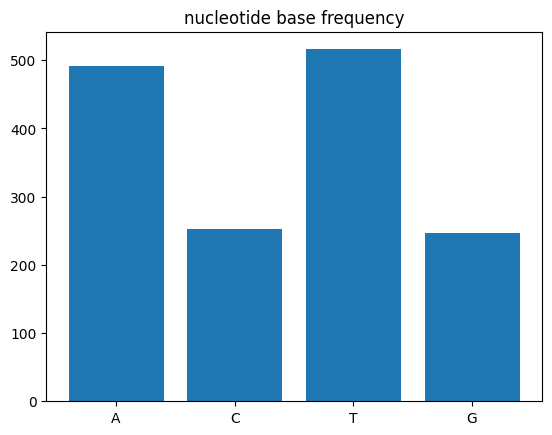

In [18]:
# 17
z_nucleotide = Counter(seq_z)
print(z_nucleotide)

plt.bar(z_nucleotide.keys(), z_nucleotide.values())
plt.title('nucleotide base frequency')
plt.show()